## <span style="color:#1F4E79;">__Sampling and Comparison-Graph Structure in the Bradley–Terry Model__</span>

__*This notebook studies how the structure of the observed comparison graph affects parameter recovery when the total comparison budget is fixed.*__

The experiment compares complete, cycle, star, two-cluster-with-bridge, and connected Erdős–Rényi graphs.


In [ ]:
# Import the libraries and reusable functions required in this notebook.
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from bradley_terry import (
    build_complete_comparison_edges,
    build_connected_erdos_renyi_edges,
    build_cycle_comparison_edges,
    build_star_comparison_edges,
    build_two_clusters_with_bridge_edges,
    center_parameters,
    comparison_graph_is_connected,
    estimate_parameters_with_gradient_descent,
    generate_comparison_data_from_edges,
    parameter_recovery_error,
)

# Shared reproducibility and display settings.
SEED = 20260831
plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.precision", 4)


##### Reusable Bradley–Terry Functions

| Function | Purpose |
|---|---|
| `center_parameters()` | Shifts parameters so their mean is zero. |
| `generate_comparison_data_from_edges()` | Generates observations using only the edges of a specified graph. |
| `build_complete_comparison_edges()` | Connects every possible pair of items. |
| `build_cycle_comparison_edges()` | Connects the items in a cycle. |
| `build_star_comparison_edges()` | Connects one central item to every other item. |
| `build_two_clusters_with_bridge_edges()` | Creates two dense groups joined by one edge. |
| `build_connected_erdos_renyi_edges()` | Generates a random connected comparison graph. |
| `comparison_graph_is_connected()` | Checks whether every item is reachable through the graph. |
| `estimate_parameters_with_gradient_descent()` | Estimates parameters by minimizing the NLL. |
| `parameter_recovery_error()` | Calculates RMSE between true and estimated parameters. |


## Experiment 1: Effect of Comparison-Graph Sampling

The number of items is fixed at 20. For each graph, the same total comparison budgets are used so that recovery can be compared under different sampling structures.


In [2]:
# Construct and summarize the comparison graphs used in Experiment 3.

sampling_number_of_items = 20
erdos_renyi_edge_probability = 0.20

sampling_graph_rng = np.random.default_rng(
    SEED + 30_000
)

comparison_graphs = {
    "Complete": build_complete_comparison_edges(
        sampling_number_of_items
    ),
    "Cycle": build_cycle_comparison_edges(
        sampling_number_of_items
    ),
    "Star": build_star_comparison_edges(
        sampling_number_of_items
    ),
    "Two clusters + bridge":
        build_two_clusters_with_bridge_edges(
            sampling_number_of_items
        ),
    "Erdos-Renyi":
        build_connected_erdos_renyi_edges(
            number_of_items=sampling_number_of_items,
            edge_probability=erdos_renyi_edge_probability,
            rng=sampling_graph_rng,
        ),
}

graph_labels = {
    graph_name: graph_name
    for graph_name in comparison_graphs
}

maximum_possible_edges = (
    sampling_number_of_items
    * (sampling_number_of_items - 1)
    // 2
)

graph_summary = []

for graph_name, edges in comparison_graphs.items():
    graph_summary.append({
        "graph": graph_name,
        "number_of_edges": len(edges),
        "edge_density": (
            len(edges) / maximum_possible_edges
        ),
        "is_connected": (
            comparison_graph_is_connected(
                sampling_number_of_items,
                edges,
            )
        ),
    })

graph_summary_table = pd.DataFrame(
    graph_summary
)

graph_summary_table

,graph,number_of_edges,edge_density,is_connected
0,Complete,190,1.0000,True
1,Cycle,20,0.1053,True
2,Star,19,0.1000,True
3,Two clusters + bridge,91,0.4789,True
4,Erdos-Renyi,36,0.1895,True


In [3]:
# Define the fixed-total-budget settings for Experiment 3.

sampling_comparison_counts = np.array([
    500,
    2_000,
    10_000,
    50_000,
])

sampling_number_of_runs = 5
sampling_learning_rate = 0.1
sampling_maximum_iterations = 2_000

sampling_experiment_settings = []

for graph_name, edges in comparison_graphs.items():
    for number_of_comparisons in sampling_comparison_counts:

        sampling_experiment_settings.append({
            "graph": graph_name,
            "number_of_edges": len(edges),
            "number_of_comparisons": (
                number_of_comparisons
            ),
            "expected_comparisons_per_edge": (
                number_of_comparisons / len(edges)
            ),
        })

sampling_experiment_settings_table = pd.DataFrame(
    sampling_experiment_settings
)

sampling_experiment_settings_table

,graph,number_of_edges,number_of_comparisons,expected_comparisons_per_edge
0,Complete,190,500,2.6316
1,Complete,190,2000,10.5263
2,Complete,190,10000,52.6316
3,Complete,190,50000,263.1579
4,Cycle,20,500,25.0000
5,Cycle,20,2000,100.0000
6,Cycle,20,10000,500.0000
7,Cycle,20,50000,2500.0000
8,Star,19,500,26.3158
9,Star,19,2000,105.2632


In [4]:
# Run the fixed-total-budget graph-sampling experiment.

sampling_run_results = []

maximum_sampling_comparisons = int(
    sampling_comparison_counts.max()
)

for run_index in range(sampling_number_of_runs):

    # Generate one true parameter vector for this run.
    parameter_rng = np.random.default_rng(
        SEED + 40_000 + run_index
    )

    true_parameters = center_parameters(
        parameter_rng.normal(
            loc=0.0,
            scale=1.0,
            size=sampling_number_of_items,
        )
    )

    for graph_index, (
        graph_name,
        edges,
    ) in enumerate(comparison_graphs.items()):

        # Use an independent but reproducible dataset for each graph.
        data_rng = np.random.default_rng(
            SEED
            + 50_000
            + run_index * 100
            + graph_index
        )

        maximum_comparison_data = (
            generate_comparison_data_from_edges(
                true_parameters=true_parameters,
                edges=edges,
                number_of_comparisons=(
                    maximum_sampling_comparisons
                ),
                rng=data_rng,
            )
        )

        for number_of_comparisons in (
            sampling_comparison_counts
        ):

            number_of_comparisons = int(
                number_of_comparisons
            )

            comparisons = maximum_comparison_data[
                :number_of_comparisons
            ]

            comparison_array = np.asarray(
                comparisons,
                dtype=int,
            )

            # Count appearances of each item.
            appearance_counts = np.bincount(
                comparison_array.ravel(),
                minlength=sampling_number_of_items,
            )

            # Count observations received by each allowed edge.
            edge_observation_counts = {
                tuple(sorted(edge)): 0
                for edge in edges
            }

            for winner, loser in comparisons:
                unordered_edge = tuple(sorted((
                    winner,
                    loser,
                )))

                edge_observation_counts[
                    unordered_edge
                ] += 1

            edge_count_array = np.asarray(
                list(edge_observation_counts.values())
            )

            estimation_start_time = perf_counter()

            estimated_parameters, nll_history = (
                estimate_parameters_with_gradient_descent(
                    sampling_number_of_items,
                    comparisons,
                    learning_rate=(
                        sampling_learning_rate
                    ),
                    maximum_iterations=(
                        sampling_maximum_iterations
                    ),
                )
            )

            estimation_time = (
                perf_counter()
                - estimation_start_time
            )

            recovery_error = parameter_recovery_error(
                true_parameters,
                estimated_parameters,
            )

            sampling_run_results.append({
                "run": run_index + 1,
                "graph": graph_name,
                "number_of_edges": len(edges),
                "number_of_comparisons": (
                    number_of_comparisons
                ),
                "expected_comparisons_per_edge": (
                    number_of_comparisons
                    / len(edges)
                ),
                "minimum_item_appearances": (
                    appearance_counts.min()
                ),
                "maximum_item_appearances": (
                    appearance_counts.max()
                ),
                "unobserved_items": (
                    np.sum(appearance_counts == 0)
                ),
                "minimum_edge_observations": (
                    edge_count_array.min()
                ),
                "observed_edge_fraction": (
                    np.mean(edge_count_array > 0)
                ),
                "recovery_error": recovery_error,
                "final_average_nll": (
                    nll_history[-1]
                ),
                "last_nll_change": abs(
                    nll_history[-1]
                    - nll_history[-2]
                ),
                "estimated_parameter_range": (
                    np.ptp(estimated_parameters)
                ),
                "estimation_seconds": estimation_time,
            })

    print(
        f"Completed sampling run "
        f"{run_index + 1}/{sampling_number_of_runs}"
    )

sampling_run_results_table = pd.DataFrame(
    sampling_run_results
)

sampling_run_results_table.head(26)

Completed sampling run 1/5
Completed sampling run 2/5
Completed sampling run 3/5
Completed sampling run 4/5
Completed sampling run 5/5


,run,graph,number_of_edges,number_of_comparisons,expected_comparisons_per_edge,minimum_item_appearances,maximum_item_appearances,unobserved_items,minimum_edge_observations,observed_edge_fraction,recovery_error,final_average_nll,last_nll_change,estimated_parameter_range,estimation_seconds
0,1,Complete,190,500,2.6316,37,66,0,0,0.9316,0.3040,0.5670,7.8445e-07,3.1274,0.4028
1,1,Complete,190,2000,10.5263,175,228,0,4,1.0000,0.1661,0.5730,4.6388e-07,3.0316,1.2643
2,1,Complete,190,10000,52.6316,922,1077,0,33,1.0000,0.0873,0.5742,4.9301e-07,2.9681,6.0566
3,1,Complete,190,50000,263.1579,4870,5130,0,219,1.0000,0.0445,0.5752,4.2703e-07,2.7501,30.5229
4,1,Cycle,20,500,25.0000,38,60,0,16,1.0000,0.6259,0.6114,2.4139e-06,2.6125,0.4019
5,1,Cycle,20,2000,100.0000,162,236,0,80,1.0000,0.5082,0.6405,1.9802e-06,2.0830,1.2911
6,1,Cycle,20,10000,500.0000,942,1081,0,461,1.0000,0.5068,0.6533,1.4838e-06,1.6807,6.2039
7,1,Cycle,20,50000,2500.0000,4889,5112,0,2411,1.0000,0.5033,0.6544,1.5533e-06,1.6865,30.4405
8,1,Star,19,500,26.3158,20,500,0,20,1.0000,0.4214,0.5958,3.4618e-06,3.5761,0.4037
9,1,Star,19,2000,105.2632,82,2000,0,82,1.0000,0.2484,0.6230,2.1690e-06,2.7587,1.3314


In [5]:
# Summarize the repeated runs for each graph and comparison budget.

sampling_summary = (
    sampling_run_results_table
    .groupby(
        ["graph", "number_of_comparisons"],
        as_index=False,
    )
    .agg(
        number_of_edges=(
            "number_of_edges",
            "first",
        ),
        mean_recovery_error=(
            "recovery_error",
            "mean",
        ),
        median_recovery_error=(
            "recovery_error",
            "median",
        ),
        standard_deviation=(
            "recovery_error",
            "std",
        ),
        mean_minimum_item_appearances=(
            "minimum_item_appearances",
            "mean",
        ),
        mean_maximum_item_appearances=(
            "maximum_item_appearances",
            "mean",
        ),
        mean_minimum_edge_observations=(
            "minimum_edge_observations",
            "mean",
        ),
        mean_observed_edge_fraction=(
            "observed_edge_fraction",
            "mean",
        ),
        mean_last_nll_change=(
            "last_nll_change",
            "mean",
        ),
        mean_parameter_range=(
            "estimated_parameter_range",
            "mean",
        ),
        mean_estimation_seconds=(
            "estimation_seconds",
            "mean",
        ),
    )
)

graph_order = list(
    comparison_graphs.keys()
)

sampling_summary["graph"] = pd.Categorical(
    sampling_summary["graph"],
    categories=graph_order,
    ordered=True,
)

sampling_summary = (
    sampling_summary
    .sort_values([
        "graph",
        "number_of_comparisons",
    ])
    .reset_index(drop=True)
)

sampling_summary[[
    "graph",
    "number_of_comparisons",
    "mean_recovery_error",
    "standard_deviation",
    "mean_minimum_item_appearances",
    "mean_observed_edge_fraction",
    "mean_last_nll_change",
    "mean_estimation_seconds",
]]

,graph,number_of_comparisons,mean_recovery_error,standard_deviation,mean_minimum_item_appearances,mean_observed_edge_fraction,mean_last_nll_change,mean_estimation_seconds
0,Complete,500,0.3055,0.0146,38.2,0.9337,1.9227e-06,0.3960
1,Complete,2000,0.1795,0.0206,173.4,1.0000,1.4173e-06,1.2871
2,Complete,10000,0.1109,0.0355,943.2,1.0000,1.1296e-06,6.1070
3,Complete,50000,0.0781,0.0327,4853.4,1.0000,1.2073e-06,30.4162
4,Cycle,500,0.5258,0.1458,39.0,1.0000,2.4272e-06,0.3912
5,Cycle,2000,0.4428,0.1004,173.0,1.0000,1.9446e-06,1.2902
6,Cycle,10000,0.4035,0.1170,943.2,1.0000,1.8975e-06,6.1308
7,Cycle,50000,0.3991,0.1101,4882.4,1.0000,1.8919e-06,30.3094
8,Star,500,0.4529,0.0953,17.2,1.0000,4.4531e-06,0.4084
9,Star,2000,0.2978,0.0502,84.8,1.0000,3.0379e-06,1.3212


In [7]:
# Helper functions for visualizing comparison graphs.

def create_circular_positions(
    items,
    center_x=0.0,
    center_y=0.0,
    radius=1.0,
):
    items = list(items)

    angles = np.linspace(
        0,
        2 * np.pi,
        len(items),
        endpoint=False,
    )

    return {
        item: (
            center_x + radius * np.cos(angle),
            center_y + radius * np.sin(angle),
        )
        for item, angle in zip(items, angles)
    }


def create_graph_positions(
    graph_name,
    number_of_items,
):
    if graph_name == "Star":
        positions = {
            0: (0.0, 0.0)
        }

        positions.update(
            create_circular_positions(
                range(1, number_of_items),
                radius=1.0,
            )
        )

        return positions

    if graph_name == "Two clusters + bridge":
        split_index = number_of_items // 2

        positions = create_circular_positions(
            range(0, split_index),
            center_x=-1.0,
            radius=0.65,
        )

        positions.update(
            create_circular_positions(
                range(split_index, number_of_items),
                center_x=1.0,
                radius=0.65,
            )
        )

        return positions

    return create_circular_positions(
        range(number_of_items)
    )


def plot_comparison_graph(
    graph_name,
    edges,
    number_of_items,
):
    positions = create_graph_positions(
        graph_name,
        number_of_items,
    )

    figure, axis = plt.subplots(
        figsize=(7, 7)
    )

    split_index = number_of_items // 2

    for item_i, item_j in edges:
        x_values = [
            positions[item_i][0],
            positions[item_j][0],
        ]

        y_values = [
            positions[item_i][1],
            positions[item_j][1],
        ]

        is_bridge = (
            graph_name == "Two clusters + bridge"
            and tuple(sorted((item_i, item_j)))
            == (split_index - 1, split_index)
        )

        axis.plot(
            x_values,
            y_values,
            color=(
                "tab:red"
                if is_bridge
                else "gray"
            ),
            linewidth=(
                2.5
                if is_bridge
                else 1.0
            ),
            alpha=(
                1.0
                if is_bridge
                else 0.45
            ),
            zorder=1,
        )

    if graph_name == "Star":
        node_colours = [
            "tab:orange" if item == 0
            else "tab:blue"
            for item in range(number_of_items)
        ]

    elif graph_name == "Two clusters + bridge":
        node_colours = [
            "tab:blue"
            if item < split_index
            else "tab:orange"
            for item in range(number_of_items)
        ]

    else:
        node_colours = [
            "tab:blue"
            for _ in range(number_of_items)
        ]

    x_positions = [
        positions[item][0]
        for item in range(number_of_items)
    ]

    y_positions = [
        positions[item][1]
        for item in range(number_of_items)
    ]

    axis.scatter(
        x_positions,
        y_positions,
        s=420,
        c=node_colours,
        edgecolors="black",
        linewidths=1.0,
        zorder=2,
    )

    for item in range(number_of_items):
        axis.text(
            positions[item][0],
            positions[item][1],
            str(item),
            ha="center",
            va="center",
            color="white",
            fontsize=9,
            fontweight="bold",
            zorder=3,
        )

    edge_density = (
        len(edges)
        / (
            number_of_items
            * (number_of_items - 1)
            / 2
        )
    )

    axis.set_title(
        f"{graph_name}\n"
        f"{len(edges)} edges, "
        f"density={edge_density:.3f}"
    )

    axis.set_aspect("equal")
    axis.axis("off")

    plt.tight_layout()
    plt.show()

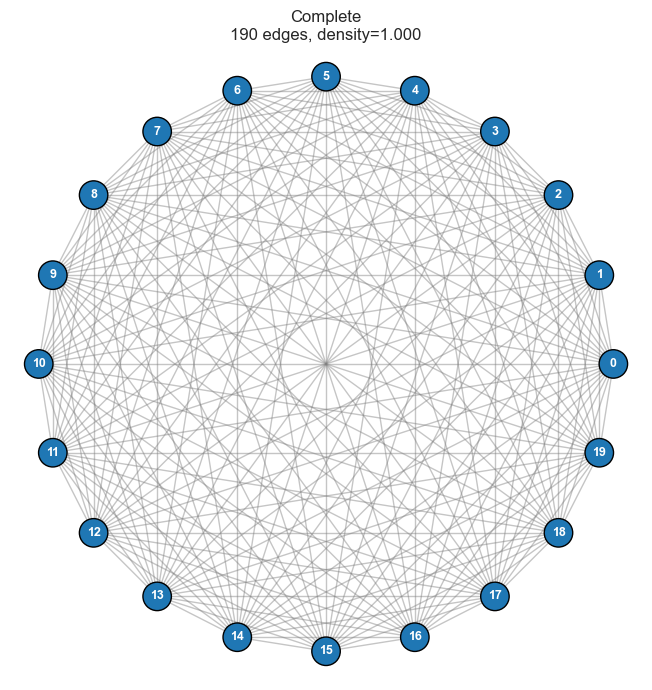

In [8]:
# complete graph
plot_comparison_graph(

    graph_name="Complete",
    edges=comparison_graphs["Complete"],
    number_of_items=sampling_number_of_items,
)

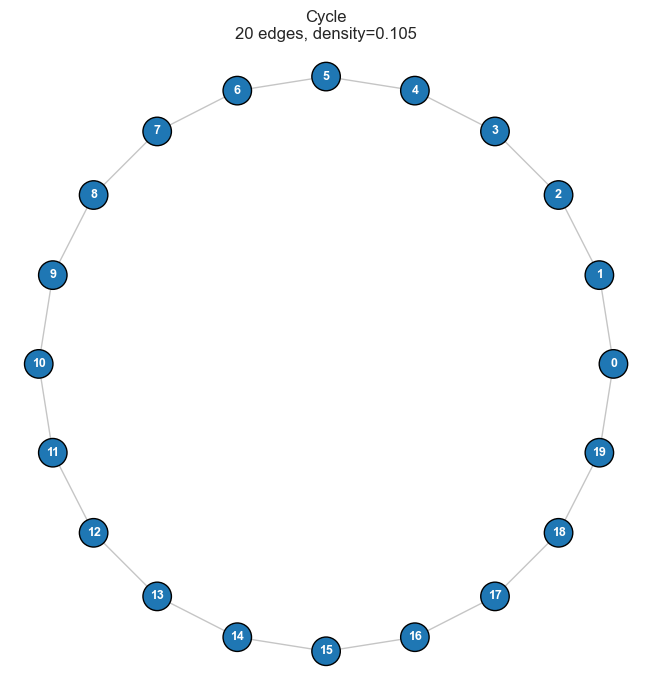

In [9]:
# cycle graph
plot_comparison_graph(
    graph_name="Cycle",
    edges=comparison_graphs["Cycle"],
    number_of_items=sampling_number_of_items,
)

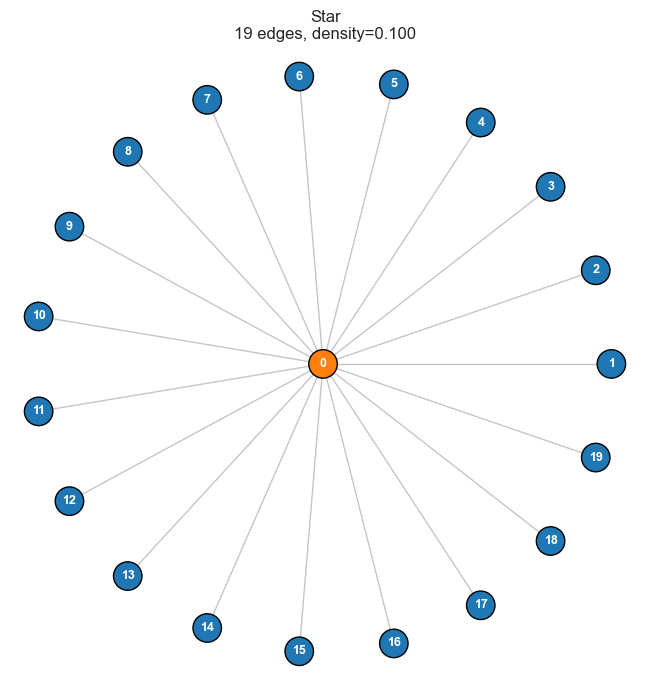

In [10]:
# satr graph
plot_comparison_graph(
    graph_name="Star",
    edges=comparison_graphs["Star"],
    number_of_items=sampling_number_of_items,
)

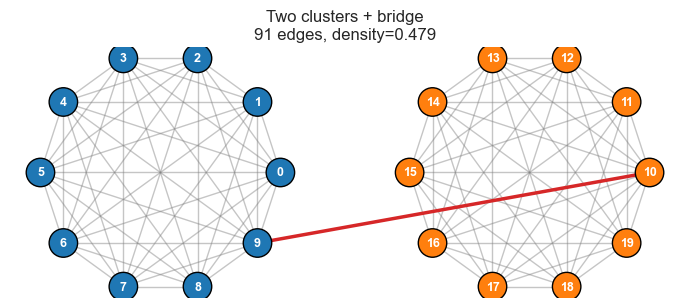

In [11]:
# two cluster with a bridge
plot_comparison_graph(
    graph_name="Two clusters + bridge",
    edges=comparison_graphs[
        "Two clusters + bridge"
    ],
    number_of_items=sampling_number_of_items,
)

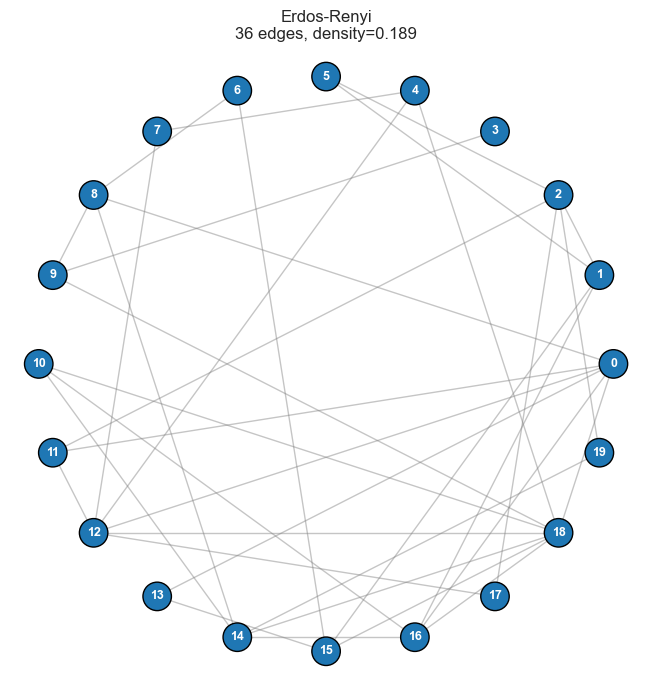

In [12]:
# rdős–Rényi graph
plot_comparison_graph(
    graph_name="Erdos-Renyi",
    edges=comparison_graphs["Erdos-Renyi"],
    number_of_items=sampling_number_of_items,
)

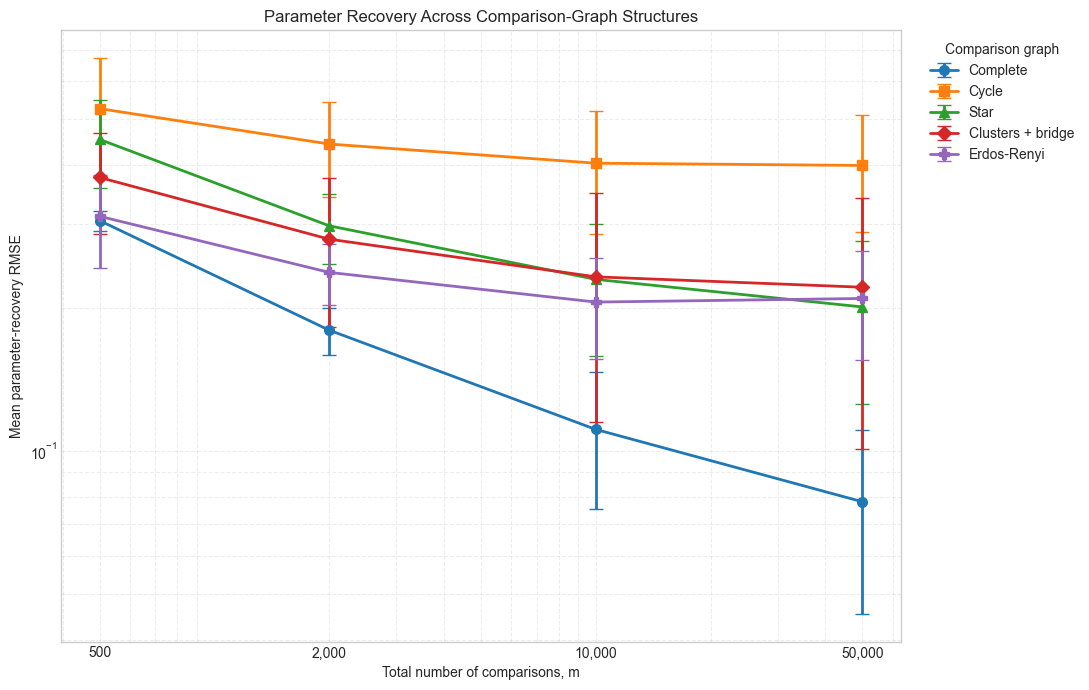

In [13]:
# Compare parameter-recovery error across graph structures.

figure, axis = plt.subplots(
    figsize=(11, 7)
)

graph_colours = {
    "Complete": "tab:blue",
    "Cycle": "tab:orange",
    "Star": "tab:green",
    "Two clusters + bridge": "tab:red",
    "Erdos-Renyi": "tab:purple",
}

graph_markers = {
    "Complete": "o",
    "Cycle": "s",
    "Star": "^",
    "Two clusters + bridge": "D",
    "Erdos-Renyi": "P",
}

for graph_name in graph_order:

    subset = sampling_summary[
        sampling_summary["graph"] == graph_name
    ].sort_values("number_of_comparisons")

    axis.errorbar(
        subset["number_of_comparisons"],
        subset["mean_recovery_error"],
        yerr=subset["standard_deviation"],
        color=graph_colours[graph_name],
        marker=graph_markers[graph_name],
        markersize=7,
        linewidth=2,
        capsize=5,
        label=graph_labels[graph_name],
    )

axis.set_xscale("log")
axis.set_yscale("log")

axis.set_xticks(
    sampling_comparison_counts
)

axis.set_xticklabels([
    f"{value:,}"
    for value in sampling_comparison_counts
])

axis.set_xlabel(
    "Total number of comparisons, m"
)

axis.set_ylabel(
    "Mean parameter-recovery RMSE"
)

axis.set_title(
    "Parameter Recovery Across Comparison-Graph Structures"
)

axis.legend(
    title="Comparison graph",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)

axis.grid(
    True,
    which="both",
    linestyle="--",
    alpha=0.35,
)

plt.tight_layout()
plt.show()

In [14]:
# Plot all individual recovery trajectories for one graph.

def plot_recovery_runs_for_graph(graph_name):

    graph_results = sampling_run_results_table[
        sampling_run_results_table["graph"]
        == graph_name
    ]

    graph_mean = sampling_summary[
        sampling_summary["graph"]
        == graph_name
    ].sort_values("number_of_comparisons")

    figure, axis = plt.subplots(
        figsize=(9, 6)
    )

    for run_number in sorted(
        graph_results["run"].unique()
    ):
        run_results = graph_results[
            graph_results["run"] == run_number
        ].sort_values("number_of_comparisons")

        axis.plot(
            run_results["number_of_comparisons"],
            run_results["recovery_error"],
            color=graph_colours[graph_name],
            marker="o",
            linewidth=1.2,
            alpha=0.30,
            label=(
                "Individual run"
                if run_number == 1
                else None
            ),
        )

    axis.plot(
        graph_mean["number_of_comparisons"],
        graph_mean["mean_recovery_error"],
        color=graph_colours[graph_name],
        marker=graph_markers[graph_name],
        markersize=8,
        linewidth=3,
        label="Mean across runs",
    )

    axis.set_xscale("log")
    axis.set_yscale("log")

    axis.set_xticks(
        sampling_comparison_counts
    )

    axis.set_xticklabels([
        f"{value:,}"
        for value in sampling_comparison_counts
    ])

    axis.set_xlabel(
        "Total number of comparisons, m"
    )

    axis.set_ylabel(
        "Parameter-recovery RMSE"
    )

    axis.set_title(
        f"{graph_labels[graph_name]} Graph: "
        "Recovery Across Individual Runs"
    )

    axis.legend()

    axis.grid(
        True,
        which="both",
        linestyle="--",
        alpha=0.35,
    )

    plt.tight_layout()
    plt.show()

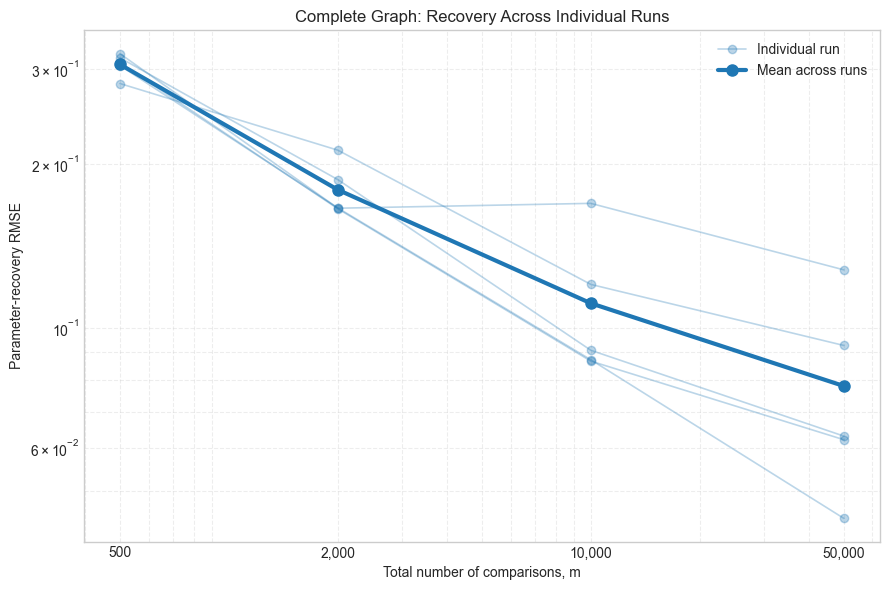

In [15]:
plot_recovery_runs_for_graph(
    "Complete"
)

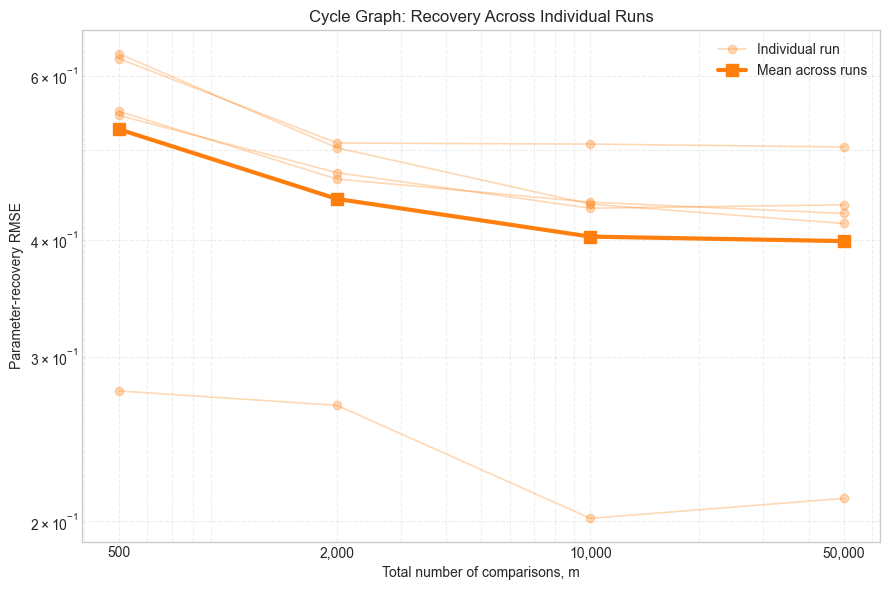

In [16]:
plot_recovery_runs_for_graph(
    "Cycle"
)

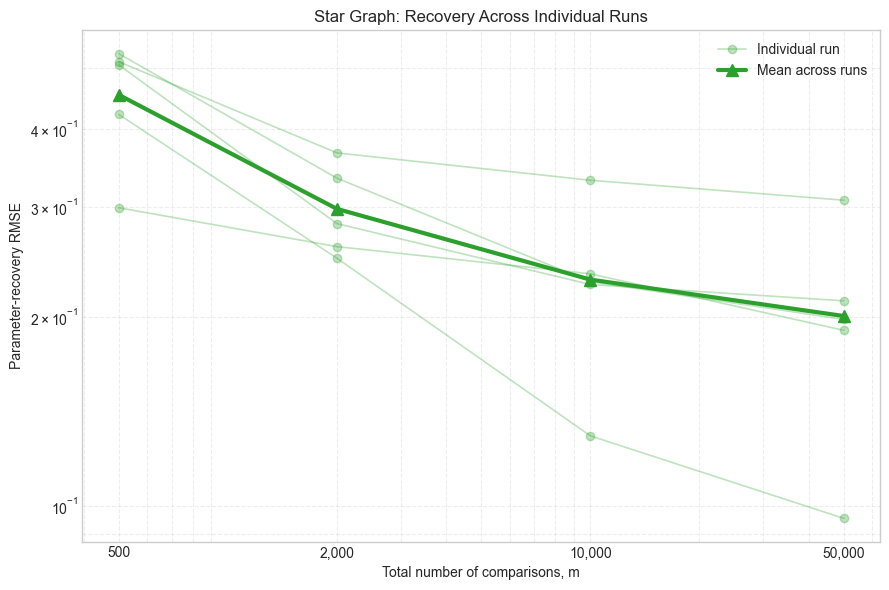

In [17]:
plot_recovery_runs_for_graph(
    "Star"
)

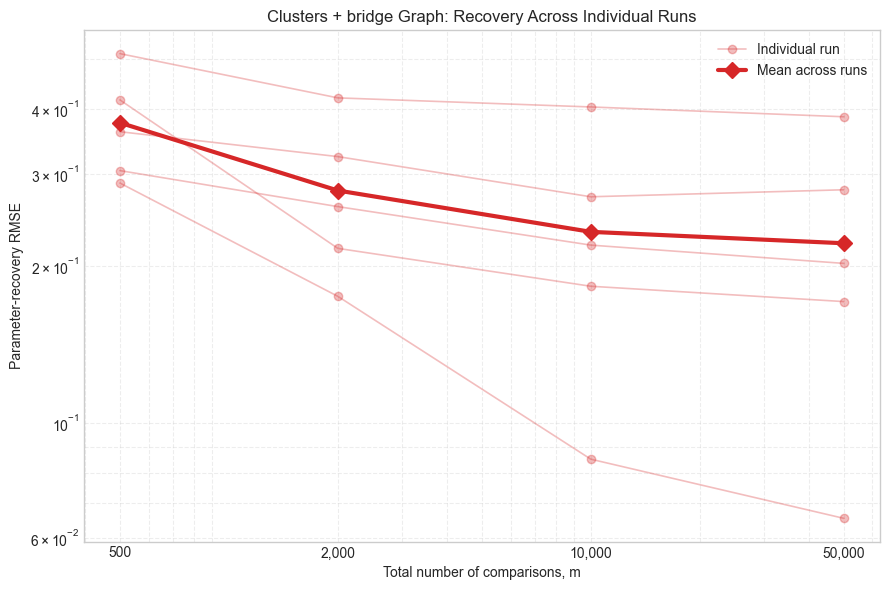

In [18]:
plot_recovery_runs_for_graph(
    "Two clusters + bridge"
)

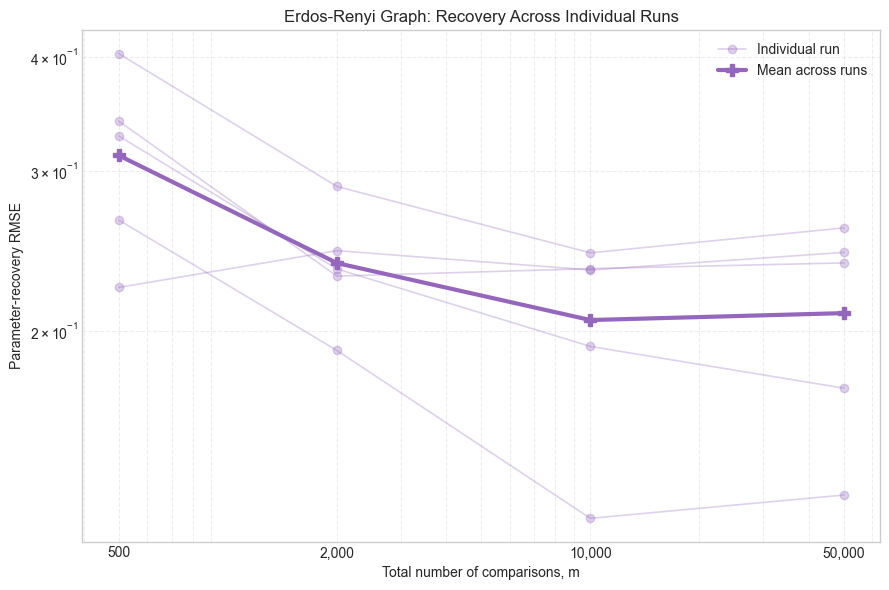

In [19]:
plot_recovery_runs_for_graph(
    "Erdos-Renyi"
)

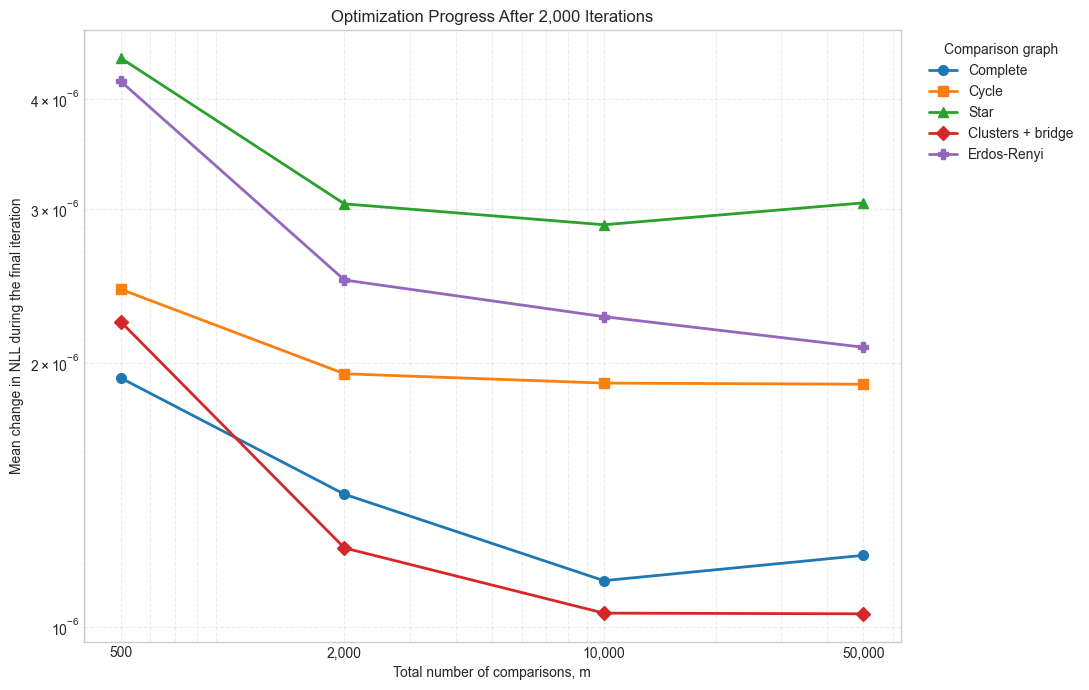

In [20]:
# Diagnose optimization progress for each graph structure.

figure, axis = plt.subplots(
    figsize=(11, 7)
)

for graph_name in graph_order:

    subset = sampling_summary[
        sampling_summary["graph"] == graph_name
    ].sort_values("number_of_comparisons")

    final_nll_changes = np.maximum(
        subset["mean_last_nll_change"],
        1e-12,
    )

    axis.plot(
        subset["number_of_comparisons"],
        final_nll_changes,
        color=graph_colours[graph_name],
        marker=graph_markers[graph_name],
        markersize=7,
        linewidth=2,
        label=graph_labels[graph_name],
    )

axis.set_xscale("log")
axis.set_yscale("log")

axis.set_xticks(
    sampling_comparison_counts
)

axis.set_xticklabels([
    f"{value:,}"
    for value in sampling_comparison_counts
])

axis.set_xlabel(
    "Total number of comparisons, m"
)

axis.set_ylabel(
    "Mean change in NLL during the final iteration"
)

axis.set_title(
    "Optimization Progress After 2,000 Iterations"
)

axis.legend(
    title="Comparison graph",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)

axis.grid(
    True,
    which="both",
    linestyle="--",
    alpha=0.35,
)

plt.tight_layout()
plt.show()

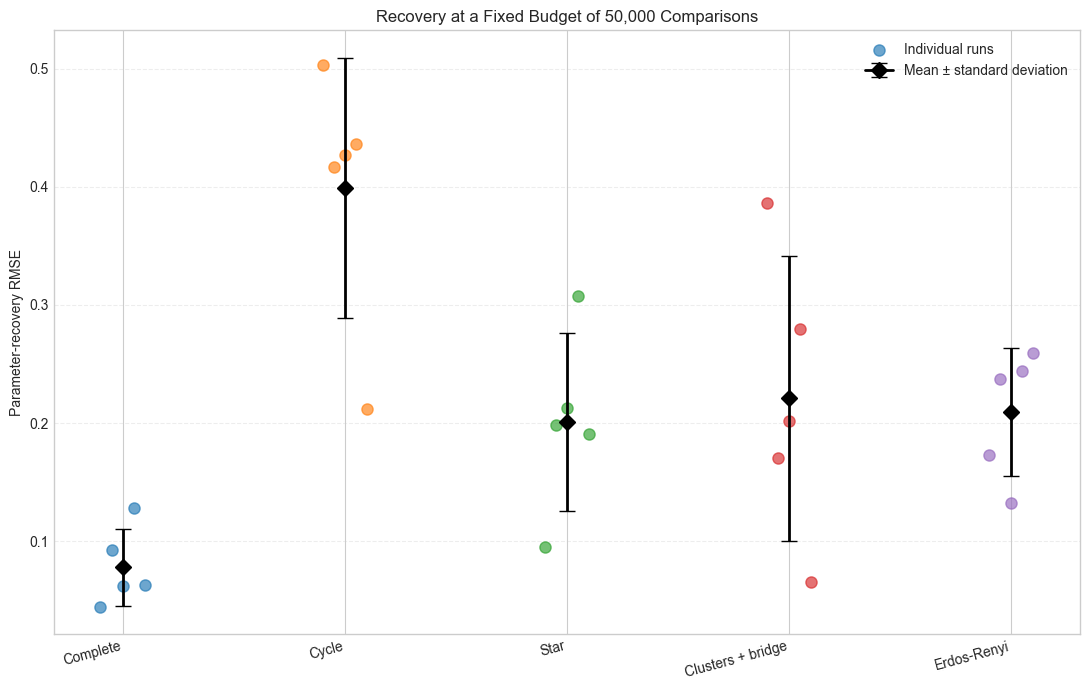

In [21]:
# Compare all graph structures at the largest fixed budget.

selected_comparison_budget = 50_000

largest_budget_results = sampling_run_results_table[
    sampling_run_results_table[
        "number_of_comparisons"
    ] == selected_comparison_budget
]

figure, axis = plt.subplots(
    figsize=(11, 7)
)

for graph_index, graph_name in enumerate(
    graph_order
):
    graph_errors = (
        largest_budget_results[
            largest_budget_results["graph"]
            == graph_name
        ]["recovery_error"]
        .to_numpy()
    )

    horizontal_offsets = np.linspace(
        -0.10,
        0.10,
        len(graph_errors),
    )

    axis.scatter(
        graph_index + horizontal_offsets,
        graph_errors,
        color=graph_colours[graph_name],
        s=65,
        alpha=0.65,
        label=(
            "Individual runs"
            if graph_index == 0
            else None
        ),
    )

    mean_error = np.mean(graph_errors)
    standard_deviation = np.std(
        graph_errors,
        ddof=1,
    )

    axis.errorbar(
        graph_index,
        mean_error,
        yerr=standard_deviation,
        color="black",
        marker="D",
        markersize=8,
        capsize=6,
        linewidth=2,
        label=(
            "Mean ± standard deviation"
            if graph_index == 0
            else None
        ),
    )

axis.set_xticks(
    range(len(graph_order))
)

axis.set_xticklabels(
    [
        graph_labels[graph_name]
        for graph_name in graph_order
    ],
    rotation=15,
    ha="right",
)

axis.set_ylabel(
    "Parameter-recovery RMSE"
)

axis.set_title(
    "Recovery at a Fixed Budget of 50,000 Comparisons"
)

axis.grid(
    axis="y",
    linestyle="--",
    alpha=0.35,
)

axis.legend()

plt.tight_layout()
plt.show()

#### Experiment 3 interpretation

